Importing the basic dependencies

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import numpy as np
import pandas as pd
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import train_test_split
from sklearn import svm
from sklearn.metrics import accuracy_score
from sklearn import metrics

Data collection

In [ ]:
new_df=pd.read_csv('/content/drive/MyDrive/Colab Notebooks/diabetes_prediction/diabetes.csv')

Data cleaning and preprocesssing

In [ ]:
#1.missing values
new_df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [ ]:
null_values = new_df.isnull()
print(null_values)

     Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin    BMI  \
0          False    False          False          False    False  False   
1          False    False          False          False    False  False   
2          False    False          False          False    False  False   
3          False    False          False          False    False  False   
4          False    False          False          False    False  False   
..           ...      ...            ...            ...      ...    ...   
763        False    False          False          False    False  False   
764        False    False          False          False    False  False   
765        False    False          False          False    False  False   
766        False    False          False          False    False  False   
767        False    False          False          False    False  False   

     DiabetesPedigreeFunction    Age  Outcome  
0                       False  False    False  
1  

In [ ]:
new_df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Diabetes - 1   |
No diabetes - 0

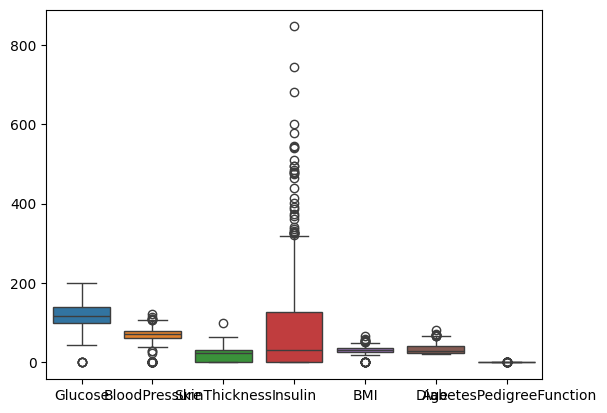

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.boxplot(data=new_df[['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI','Age','DiabetesPedigreeFunction']])
plt.show()

In [ ]:
#handling the outliers
from scipy import stats
new_df = new_df[(np.abs(stats.zscore(new_df)) < 3).all(axis=1)]

In [ ]:
upper_limit = new_df['Glucose'].quantile(0.95)
new_df['Glucose'] = np.where(new_df['Glucose'] > upper_limit, upper_limit, new_df['Glucose'])

<ipython-input-10-0eb895d1d689>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df['Glucose'] = np.where(new_df['Glucose'] > upper_limit, upper_limit, new_df['Glucose'])


In [ ]:
upper_limit = new_df['Insulin'].quantile(0.95)
new_df['Insulin'] = np.where(new_df['Insulin'] > upper_limit, upper_limit, new_df['Insulin'])

<ipython-input-11-d285757dd3aa>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df['Insulin'] = np.where(new_df['Insulin'] > upper_limit, upper_limit, new_df['Insulin'])


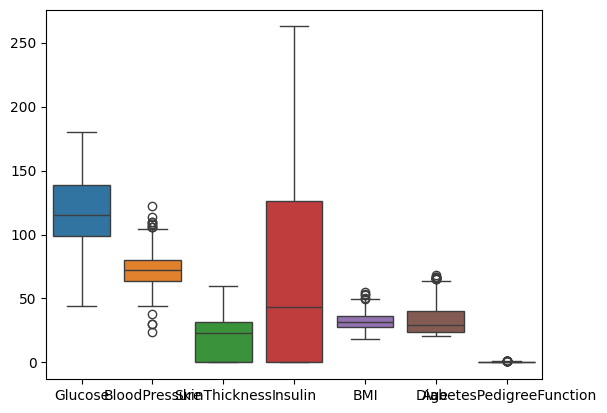

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.boxplot(data=new_df[['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI','Age','DiabetesPedigreeFunction']])
plt.show()

In [ ]:
new_df.Age[1]

np.int64(31)

In [ ]:
new_df['Age'].values

array([50, 31, 32, 21, 30, 26, 30, 34, 57, 51, 31, 31, 33, 32, 27, 50, 41,
       29, 51, 41, 43, 22, 57, 38, 60, 28, 22, 28, 45, 33, 35, 46, 27, 56,
       26, 37, 48, 54, 40, 29, 22, 31, 22, 26, 30, 58, 42, 21, 41, 31, 22,
       39, 36, 24, 42, 32, 38, 54, 25, 27, 28, 26, 42, 23, 22, 41, 27, 24,
       22, 36, 22, 37, 27, 45, 26, 24, 21, 34, 42, 60, 21, 40, 24, 22, 23,
       31, 33, 22, 21, 24, 27, 21, 27, 37, 25, 24, 24, 23, 25, 39, 61, 38,
       25, 22, 21, 25, 24, 23, 23, 26, 30, 23, 40, 62, 33, 33, 30, 39, 26,
       31, 21, 22, 29, 28, 55, 38, 22, 42, 23, 41, 34, 65, 22, 24, 37, 42,
       43, 36, 21, 23, 22, 36, 45, 27, 21, 32, 41, 22, 34, 29, 29, 36, 29,
       23, 33, 36, 42, 47, 37, 32, 23, 27, 40, 41, 33, 31, 25, 21, 40, 36,
       42, 29, 21, 23, 26, 29, 21, 28, 32, 27, 55, 27, 57, 52, 21, 41, 25,
       24, 60, 24, 36, 38, 25, 32, 32, 41, 66, 61, 26, 22, 26, 24, 24, 22,
       46, 22, 29, 23, 26, 51, 23, 32, 27, 21, 22, 22, 33, 29, 49, 41, 34,
       23, 42, 27, 24, 25

In [ ]:
#getting the dimensions of the data
new_df.shape

(688, 9)

In [ ]:
#getting the statistical measures on the data
new_df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,688.000000,688.000000,688.000000,688.000000,688.000000,688.000000,688.000000,688.000000,688.000000
mean,3.845930,119.827035,72.345930,20.787791,69.769259,32.209157,0.454555,33.094477,0.329942
std,3.279256,28.956686,12.312859,15.405391,82.667870,6.618891,0.284527,11.436990,0.470534
min,0.000000,44.000000,24.000000,0.000000,0.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,64.000000,0.000000,0.000000,27.400000,0.245000,24.000000,0.000000
50%,3.000000,115.000000,72.000000,23.000000,43.500000,32.000000,0.370000,29.000000,0.000000
75%,6.000000,139.000000,80.000000,32.000000,126.000000,36.300000,0.605500,40.000000,1.000000
max,13.000000,180.000000,122.000000,60.000000,262.550000,55.000000,1.461000,68.000000,1.000000


In [ ]:
new_df['Outcome'].value_counts()

,count
Outcome,
0,461
1,227


Using statistical measure(Mean)and grouping the whole data based on Outcome"

In [ ]:
new_df.groupby('Outcome').mean()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Outcome,,,,,,,,
0,3.325380,110.114967,70.770065,20.175705,63.250434,30.825813,0.411885,31.119306
1,4.903084,139.550661,75.546256,22.030837,83.007930,35.018502,0.541211,37.105727


In [ ]:
#separating the label(Outcome) and data (remaining all)
x=new_df.drop(columns='Outcome', axis=1)
y=new_df['Outcome']


In [ ]:
print(x)

     Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0              6    148.0             72             35      0.0  33.6   
1              1     85.0             66             29      0.0  26.6   
2              8    180.0             64              0      0.0  23.3   
3              1     89.0             66             23     94.0  28.1   
5              5    116.0             74              0      0.0  25.6   
..           ...      ...            ...            ...      ...   ...   
763           10    101.0             76             48    180.0  32.9   
764            2    122.0             70             27      0.0  36.8   
765            5    121.0             72             23    112.0  26.2   
766            1    126.0             60              0      0.0  30.1   
767            1     93.0             70             31      0.0  30.4   

     DiabetesPedigreeFunction  Age  
0                       0.627   50  
1                       0.351   31  


In [ ]:
print(y)

0      1
1      0
2      1
3      0
5      0
      ..
763    0
764    0
765    0
766    1
767    0
Name: Outcome, Length: 688, dtype: int64


**Data standardization** comes into the picture when features of the input data set have large differences between their ranges, or simply when they are measured in different units. These differences in the ranges of initial features cause trouble for many machine learning models

In [ ]:
scaler = StandardScaler()
scaler.fit(x)

standardized_data = scaler.transform(x)

In [ ]:
x= standardized_data
print(x)
print(y)

[[ 0.65735547  0.97364255 -0.02811548 ...  0.21028523  0.60651604
   1.47921983]
 [-0.86848989 -1.20360363 -0.51576543 ... -0.84806325 -0.36422044
  -0.18326505]
 [ 1.26769361  2.07954537 -0.67831541 ... -1.34699896  0.76478829
  -0.09576584]
 ...
 [ 0.3521864   0.04053704 -0.02811548 ... -0.90854031 -0.73703952
  -0.27076425]
 [-0.86848989  0.21333436 -1.00341538 ... -0.31888901 -0.37125476
   1.21672222]
 [-0.86848989 -0.92712792 -0.19066546 ... -0.27353122 -0.49083824
  -0.88325868]]
0      1
1      0
2      1
3      0
5      0
      ..
763    0
764    0
765    0
766    1
767    0
Name: Outcome, Length: 688, dtype: int64


**Train ,Test  and split**


The model was overfitted to the training data.

The feature engineering or preprocessing was flawed.







In [ ]:
train_x,test_x,train_y,test_y = train_test_split(x,y,test_size=0.2 , stratify=y ,random_state=42)  # 80% train, 20% test
train_x =scaler.fit_transform(train_x)
test_x =scaler.transform(test_x)

In [ ]:
print(x.shape,train_x.shape,test_x.shape)

(688, 8) (550, 8) (138, 8)


***Training the model***

A Support Vector Machine (SVM) is a powerful machine learning algorithm widely used for both linear and nonlinear classification, as well as regression and outlier detection tasks.

A robust model is one that performs well even when faced with new, unseen data or data that contains noise or outliers.

In [ ]:
classifier = svm.SVC( kernel ='linear') #C is a the regulation parameter

In [ ]:
# training the Support Vector machine Classisfier
classifier.fit(train_x,train_y)

SVC(kernel='linear')

Accuracy of the Train data and test data

In [ ]:
# Add cross-validation
from sklearn.model_selection import cross_val_score
cv_scores = cross_val_score(classifier, x, y, cv=5)
print(f"Cross-validation scores: {cv_scores}")
print(f"Mean CV accuracy: {cv_scores.mean():.2f}")

# Try different kernels
from sklearn.svm import SVC
kernels = ['linear', 'rbf', 'poly']
for kernel in kernels:
    model = SVC(kernel=kernel, probability=True)
    model.fit(train_x, train_y)
    print(f"Kernel: {kernel}, Test Accuracy: {model.score(test_x, test_y):.2f}")

# Add feature importance analysis (for linear kernel)
if hasattr(classifier, 'coef_'):
    feature_importance = pd.DataFrame({
        'Feature': new_df.drop(columns='Outcome').columns,
        'Importance': classifier.coef_[0]
    }).sort_values('Importance', ascending=False)
    print(feature_importance)

Cross-validation scores: [0.77536232 0.76811594 0.76811594 0.82481752 0.7810219 ]
Mean CV accuracy: 0.78
Kernel: linear, Test Accuracy: 0.79
Kernel: rbf, Test Accuracy: 0.78
Kernel: poly, Test Accuracy: 0.80
                    Feature  Importance
1                   Glucose    0.900812
5                       BMI    0.568281
6  DiabetesPedigreeFunction    0.318919
0               Pregnancies    0.244289
7                       Age    0.090822
2             BloodPressure   -0.082447
3             SkinThickness   -0.109052
4                   Insulin   -0.112917


In [ ]:
#accuracy of the model

In [ ]:
train_x_prediction = classifier.predict(train_x)
train_data_accuracy = accuracy_score(train_x_prediction,train_y)

In [ ]:
train_data_accuracy

0.7854545454545454

In [ ]:
test_x_prediction = classifier.predict(test_x)
test_data_accuracy = accuracy_score(test_x_prediction,test_y)

In [ ]:
test_data_accuracy

0.7898550724637681

**Classification Report**

In [ ]:
from sklearn.metrics import classification_report


y_pred = model.predict(test_x)  # Get predictions for the test data
print("Classification report")
# Generate the classification report
report = classification_report(test_y, y_pred)

# Print the report
print(report)

Classification report
              precision    recall  f1-score   support

           0       0.79      0.95      0.86        92
           1       0.82      0.50      0.62        46

    accuracy                           0.80       138
   macro avg       0.81      0.72      0.74       138
weighted avg       0.80      0.80      0.78       138



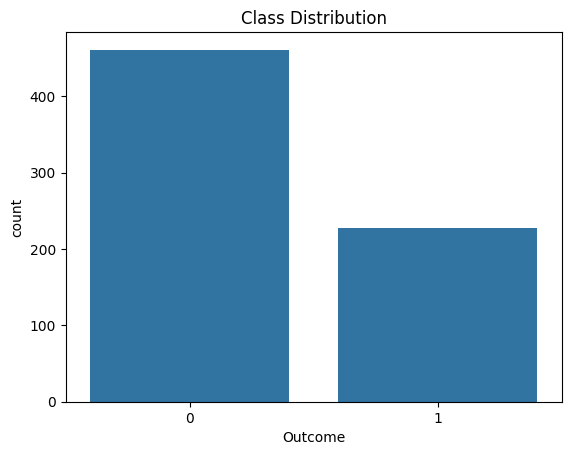

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='Outcome', data=new_df)
plt.title('Class Distribution')
plt.show()

**Confusion Matrix**

The confusion matrix provides a clear visual representation of how well your model is classifying instances

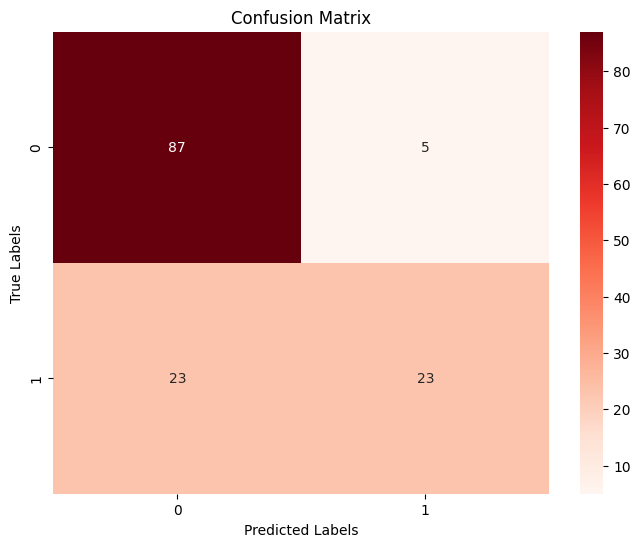

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix


y_pred = model.predict(test_x)  # Get predictions for the test data

# Generate the confusion matrix
cm = confusion_matrix(test_y, y_pred)

# Create a heatmap for visualization
plt.figure(figsize=(8, 6))  # Adjust figure size if needed
sns.heatmap(cm, annot=True, fmt="d", cmap="Reds")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.title("Confusion Matrix")
plt.show()

 **Receiver Operating Characteristic (ROC) curve**

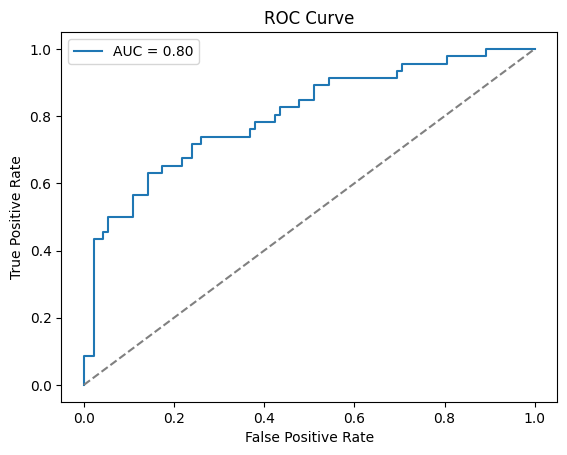

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Assuming 'classifier' is your trained model,
# 'test_x' is your test data, and 'test_y' are the true labels for the test data

# Get predicted probabilities for the positive class (class 1, diabetic)
y_probs = model.predict_proba(test_x)[:, 1]

# Calculate ROC curve values
fpr, tpr, thresholds = roc_curve(test_y, y_probs)

# Calculate AUC (Area Under the Curve)
auc = roc_auc_score(test_y, y_probs)

# Plot the ROC curve
plt.plot(fpr, tpr, label=f'AUC = {auc:.2f}')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')  # Diagonal line for random classifier
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

Box-Plot representation


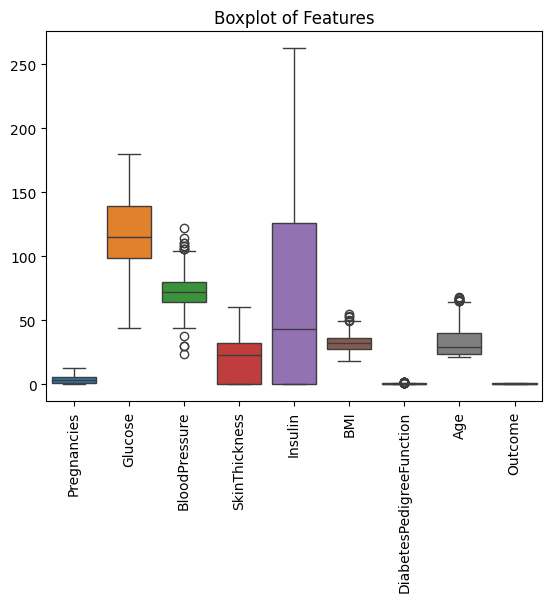

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt



# Create a boxplot for all features
sns.boxplot(data=new_df)
plt.xticks(rotation=90)
plt.title('Boxplot of Features')
plt.show()

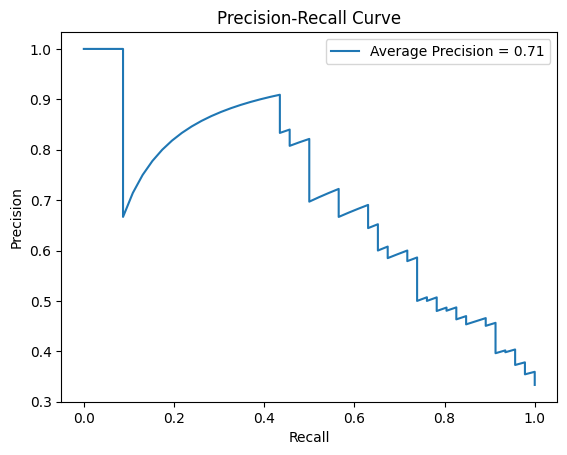

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt



y_probs = model.predict_proba(test_x)[:, 1] # Get predicted probabilities for the positive class

precision, recall, thresholds = precision_recall_curve(test_y, y_probs)
average_precision = average_precision_score(test_y, y_probs)

plt.plot(recall, precision, label=f'Average Precision = {average_precision:.2f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()

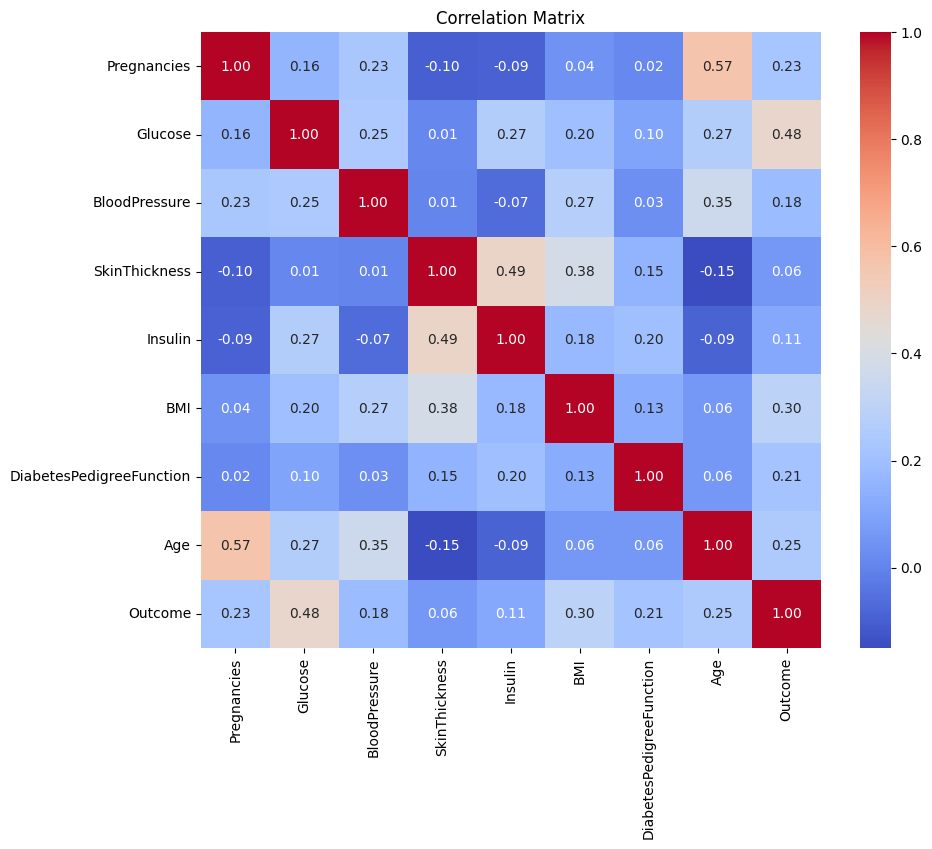

In [ ]:
correlation_matrix = new_df.corr()
plt.figure(figsize=(10, 8))  # Adjust the figure size if needed
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

Predictive System

In [ ]:
input_data = (3,122,78,0,0,23,0.254,40)

#changing the input_data in to numpy arrry
input_data_array = np.asarray(input_data)
#reshape the array
reshaped_input_data = input_data_array.reshape(1,-1)

#standardize the data
std_input_data = scaler.transform(reshaped_input_data)

prediction = classifier.predict(std_input_data)

if prediction[0] == 0:
  print("the person is not diabatic(-ve)")
else:
  print("the person is diabatic(+ve)")

print(f"Model Accuracy:{test_data_accuracy*100:.2f}%")

the person is diabatic(+ve)
Model Accuracy:78.99%


# Another Models

In [ ]:
#using RandomForestclassifier

In [ ]:
robust_scaler = RobustScaler()
robust_scaler.fit(x)
standardized_data = robust_scaler.transform(x)

In [ ]:
train_x,test_x,train_y,test_y = train_test_split(x,y,test_size=0.2 , stratify=y ,random_state=42)  # 80% train, 20% test
train_x =robust_scaler.fit_transform(train_x)
test_x =robust_scaler.transform(test_x)

In [ ]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import PolynomialFeatures



# Initialize and train a RandomForestClassifier
rmodel = RandomForestClassifier(random_state=42)


In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(train_x,train_y)

rmodel.fit(X_train_resampled, y_train_resampled)


RandomForestClassifier(random_state=42)

In [ ]:
test_x_prediction = rmodel.predict(test_x)
test_data_accuracy = accuracy_score(test_x_prediction,test_y)
test_data_accuracy

0.746268656716418

In [ ]:
# Make predictions on the test set
test_x_prediction = rmodel.predict(test_x)

# Evaluate the model's accuracy
test_data_accuracy = accuracy_score(test_x_prediction,test_y)
print(f"Test Accuracy: {test_data_accuracy*100:.2f}%")

Test Accuracy: 74.63%


In [ ]:
#using the Logistic Regression

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score



# Create and train the model
lmodel = LogisticRegression()
lmodel.fit(train_x, train_y)

# Make predictions
y_pred = lmodel.predict(test_x)

# Evaluate the model
accuracy = accuracy_score(test_y, y_pred)
print(f"Accuracy: {accuracy}")

Accuracy: 0.8432835820895522


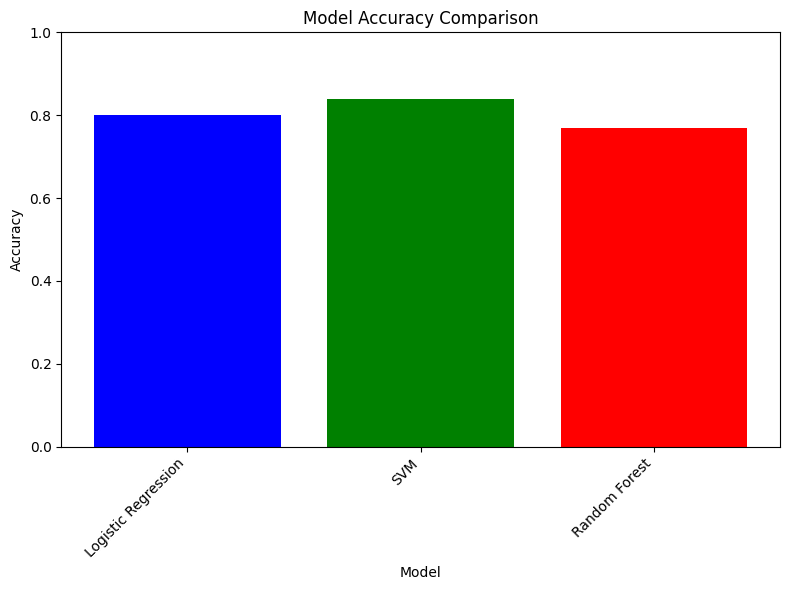

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Assuming you have accuracy scores for different models in a dictionary
model_accuracies = {
    'Logistic Regression': 0.80,
    'SVM': 0.84,
    'Random Forest': 0.77,

}

model_names = list(model_accuracies.keys())
accuracies = list(model_accuracies.values())

plt.figure(figsize=(8, 6))  # Adjust figure size if needed
plt.bar(model_names, accuracies, color=['blue', 'green', 'red'])
plt.title('Model Accuracy Comparison')
plt.xlabel('Model')
plt.ylabel('Accuracy')
plt.ylim(0, 1)  # Set y-axis limits for better visualization
plt.xticks(rotation=45, ha='right')  # Rotate x-axis labels if needed
plt.tight_layout()  # Adjust layout for better spacing
plt.show()